In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Size": [800, 1000, 1200, 1500, 1800,
             2000, 2200, 2500, 2700, 3000],
    "Bedrooms": [2, 2, 3, 3, 3, 4, 4, 4, 5, 5],
    "Age": [10, 8, 5, 7, 4, 6, 3, 2, 5, 1],
    "Price": [40, 50, 60, 70, 85, 95, 105, 120, 130, 145]
}

df = pd.DataFrame(data)

df.head()

,Size,Bedrooms,Age,Price
0,800,2,10,40
1,1000,2,8,50
2,1200,3,5,60
3,1500,3,7,70
4,1800,3,4,85


In [2]:
X = df[["Size", "Bedrooms", "Age"]]
y = df["Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10, 3)
Target shape: (10,)


In [3]:
print(df.describe())
print(df.corr().round(2))

              Size   Bedrooms        Age       Price
count    10.000000  10.000000  10.000000   10.000000
mean   1870.000000   3.500000   5.100000   90.000000
std     743.938468   1.080123   2.766867   35.276684
min     800.000000   2.000000   1.000000   40.000000
25%    1275.000000   3.000000   3.250000   62.500000
50%    1900.000000   3.500000   5.000000   90.000000
75%    2425.000000   4.000000   6.750000  116.250000
max    3000.000000   5.000000  10.000000  145.000000
          Size  Bedrooms   Age  Price
Size      1.00      0.96 -0.84   1.00
Bedrooms  0.96      1.00 -0.76   0.96
Age      -0.84     -0.76  1.00  -0.84
Price     1.00      0.96 -0.84   1.00


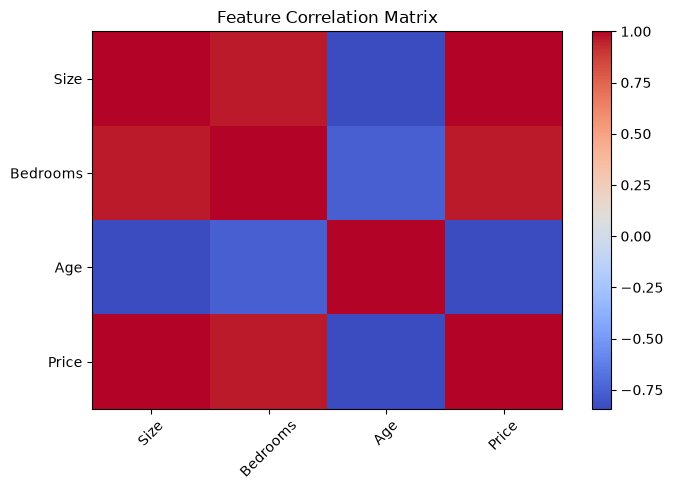

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.imshow(df.corr(), cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(range(len(df.columns)), df.columns, rotation=45)
plt.yticks(range(len(df.columns)), df.columns)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (8, 3)
Testing: (2, 3)


In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.04, 1.79,-0.4 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Size','Bedrooms','Age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.394
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [7]:
print("Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

print("Intercept:", model.intercept_)

Coefficients:
Size: 0.0438
Bedrooms: 1.7925
Age: -0.3953
Intercept: 3.393980233602875


In [8]:
new_house = pd.DataFrame({
    "Size": [2000],
    "Bedrooms": [4],
    "Age": [3]
})

prediction = model.predict(new_house)

print(f"Predicted house price: ₹{prediction[0]:.2f} lakhs")

Predicted house price: ₹97.07 lakhs


In [9]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 1.7879604672057532
MSE: 3.499648643128796
RMSE: 1.870734786956397
R2: 0.9978127195980445


In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

scaled_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

scaled_model.fit(X_train, y_train)

scaled_predictions = scaled_model.predict(X_test)